# Task 03: Customer Churn Prediction

## Project Overview

This project aims to predict customer churn using telecommunications subscription data.

Customer churn occurs when customers stop using a company's services. Predicting churn helps businesses identify customers who are likely to leave and take preventive actions.

## Objectives

- Load and explore the Telco Customer Churn dataset.
- Perform data cleaning and preprocessing.
- Convert `TotalCharges` into a numeric feature.
- Handle missing values.
- Encode categorical features using OneHotEncoder.
- Handle class imbalance using class weighting.
- Train Random Forest and XGBoost classifiers.
- Evaluate models using classification metrics and ROC-AUC.
- Visualize confusion matrices and ROC curves.
- Identify the top 10 most important features.

## Machine Learning Models

1. Random Forest Classifier
2. XGBoost Classifier

## 1. Import Libraries

Import the required libraries for data manipulation, visualization, preprocessing, model training, and evaluation.

In [1]:

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine Learning Models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Load Dataset

Load the Telco Customer Churn dataset from its online source and display the first few records.

The dataset contains customer information, subscription services, billing details, and churn status.

In [2]:

# Dataset URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load dataset
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Dataset Information

Inspect the dataset structure, column names, data types, and memory usage.

This step helps us understand the available features and identify columns that require preprocessing.

In [3]:

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 4. Statistical Summary

Generate descriptive statistics for numerical and categorical columns to understand their distributions and values.

In [4]:

# Numerical columns
display(df.describe().T)

# Categorical columns
display(df.describe(include="object").T)


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


## 5. Missing Values Analysis

Check the number and percentage of missing values in each column.

Identifying missing data is important before training machine learning models.

In [5]:

# Calculate missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_values)


,Missing Values,Percentage
customerID,0,0.0
DeviceProtection,0,0.0
TotalCharges,0,0.0
MonthlyCharges,0,0.0
PaymentMethod,0,0.0
PaperlessBilling,0,0.0
Contract,0,0.0
StreamingMovies,0,0.0
StreamingTV,0,0.0
TechSupport,0,0.0


## 6. Duplicate Records

Check whether the dataset contains duplicated customer records.

In [6]:

# Count duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)


Number of duplicated rows: 0


## 7. Target Variable Distribution

Analyze the distribution of the target variable, Churn.

This helps identify whether the dataset has an imbalanced class distribution.

Churn Distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn Percentage:


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

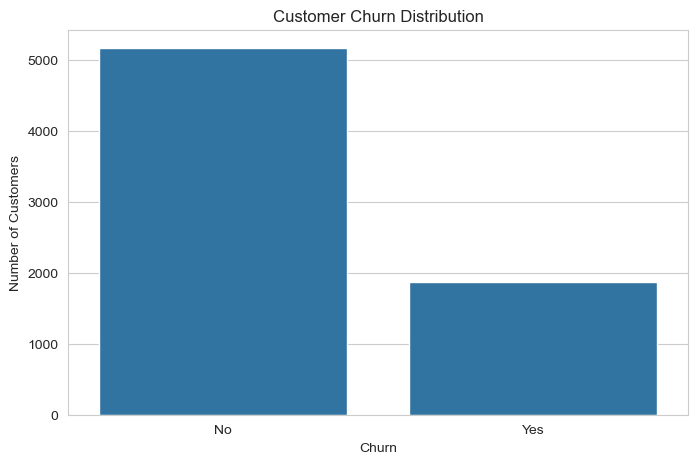

In [7]:

# Churn distribution
churn_counts = df["Churn"].value_counts()

print("Churn Distribution:")
display(churn_counts)

# Calculate percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn Percentage:")
display(churn_percentage)

# Visualize distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()


## 8. Numerical Features Distribution

Visualize the distributions of numerical customer attributes to understand their patterns and detect potential outliers.

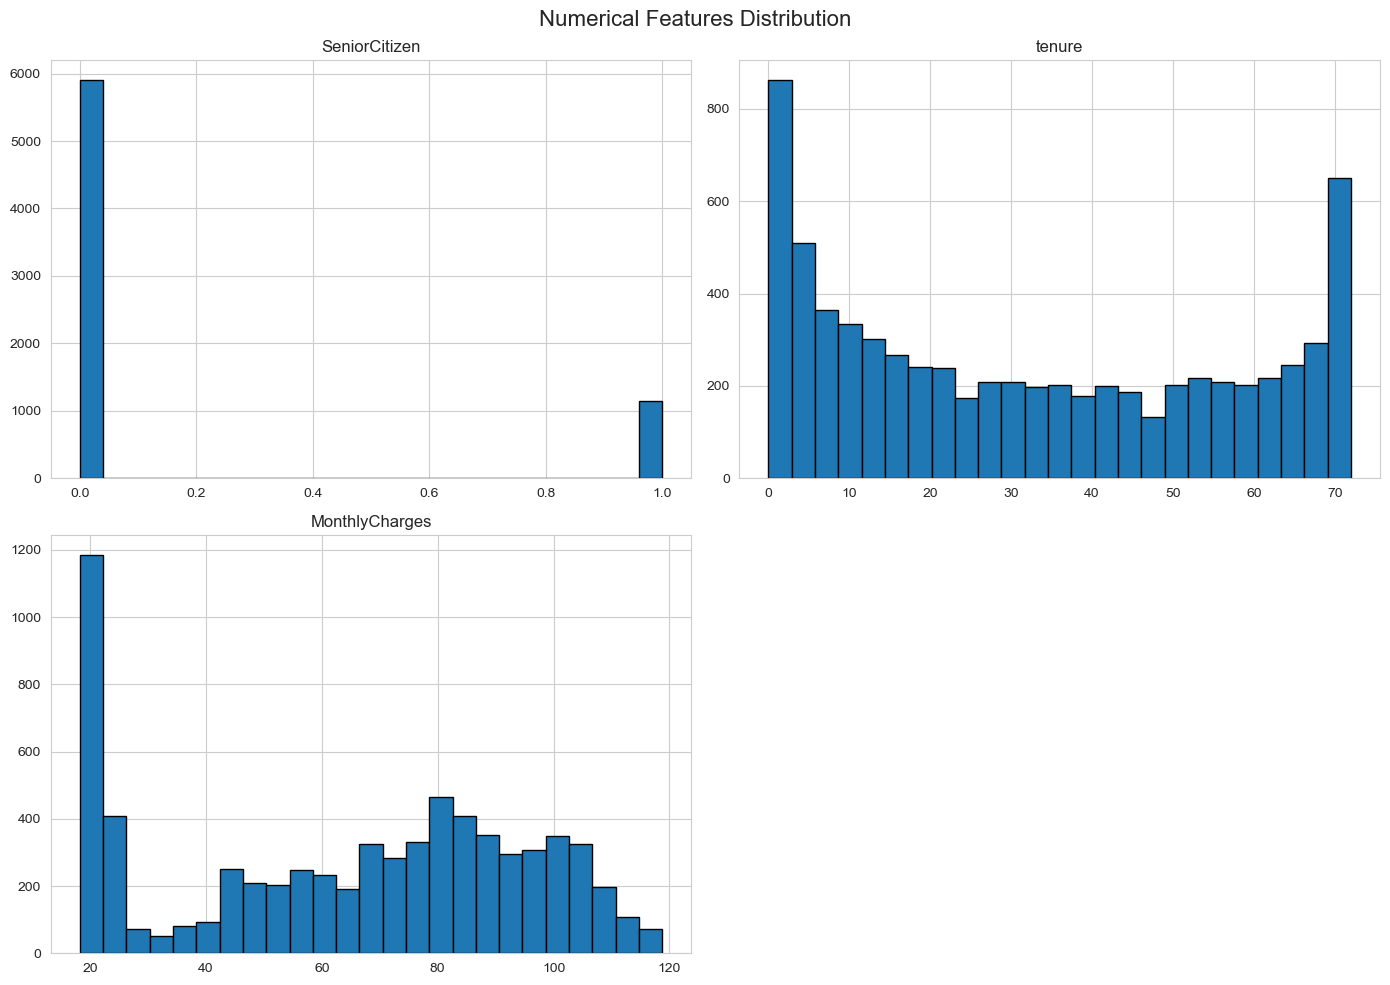

In [8]:

# Select numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Plot distributions
df[numerical_columns].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distribution", fontsize=16)
plt.tight_layout()
plt.show()


## 9. Categorical Features Analysis

Explore categorical features to understand the distribution of customer demographics, subscribed services, and payment methods.

In [9]:

# Select categorical columns
categorical_columns = df.select_dtypes(include="object").columns

# Display unique values
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts().head(10))



customerID:
customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
5855-EIBDE    1
8166-ZZTFS    1
0129-KPTWJ    1
9128-CPXKI    1
9509-MPYOD    1
Name: count, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service  

## 10. Churn Analysis by Contract Type

Analyze the relationship between contract type and customer churn.

This helps identify whether customers with different contract durations have different churn rates.

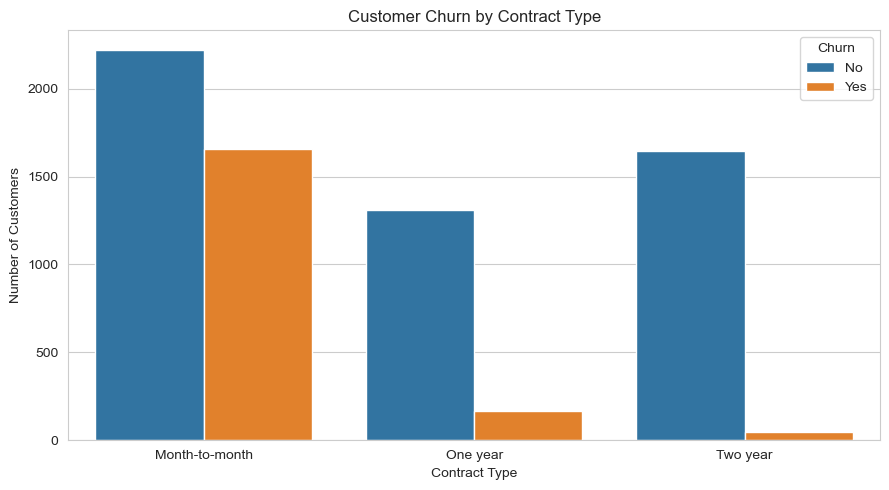

In [10]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


## 11. Data Cleaning

Clean the dataset by converting `TotalCharges` into a numeric column and handling invalid or missing values.

The `customerID` column is an identifier and will be excluded from model training because it does not provide meaningful predictive information.

In [11]:

# Create a copy of the dataset
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Drop customer ID
df_clean.drop(columns=["customerID"], inplace=True)

# Check missing values after conversion
print("Missing values after conversion:")
display(df_clean.isnull().sum().sort_values(ascending=False).head(10))

print("\nCleaned dataset shape:", df_clean.shape)


Missing values after conversion:


TotalCharges        11
gender               0
SeniorCitizen        0
MonthlyCharges       0
PaymentMethod        0
PaperlessBilling     0
Contract             0
StreamingMovies      0
StreamingTV          0
TechSupport          0
dtype: int64


Cleaned dataset shape: (7043, 20)


## 12. Prepare Features and Target

Separate the input features from the target variable.

The target column `Churn` will be converted into binary values:

- No = 0
- Yes = 1

In [12]:

# Separate features and target
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())


Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:


Churn
0    5174
1    1869
Name: count, dtype: int64

## 13. Train-Test Split

Split the dataset into training and testing sets.

Stratified sampling is used to preserve the original churn class distribution in both sets.

In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True) * 100)


Training set shape: (5634, 19)
Testing set shape: (1409, 19)

Training target distribution:


Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64


Testing target distribution:


Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64

## 14. Identify Numerical and Categorical Features

Identify numerical and categorical columns to apply the appropriate preprocessing techniques.

Numerical features will be imputed using the median, while categorical features will be imputed using the most frequent value and encoded using OneHotEncoder.

In [14]:

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


## 15. Build Preprocessing Pipelines

Build separate preprocessing pipelines for numerical and categorical features.

- Numerical features: Median imputation and standard scaling.
- Categorical features: Most frequent imputation and OneHotEncoder.

A ColumnTransformer combines both pipelines. All preprocessing steps are fitted only on training data through the model pipeline to prevent data leakage.

In [15]:

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


## 16. Handle Class Imbalance

The target variable contains an unequal number of churn and non-churn customers.

Calculate the class imbalance ratio using the training data. This ratio will be used as the `scale_pos_weight` parameter for XGBoost, while Random Forest will use balanced class weights.

In [16]:

# Calculate class distribution from training data
class_counts = y_train.value_counts()

negative_count = class_counts[0]
positive_count = class_counts[1]

# Calculate imbalance ratio
scale_pos_weight = negative_count / positive_count

print("Non-Churn Customers:", negative_count)
print("Churn Customers:", positive_count)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 3))


Non-Churn Customers: 4139
Churn Customers: 1495
XGBoost scale_pos_weight: 2.769


## Model Training
## 17. Random Forest Classifier

Train a Random Forest ensemble classifier using the preprocessing pipeline.

The `class_weight="balanced"` parameter automatically adjusts class weights based on their frequencies in the training data.

In [17]:

# Create Random Forest pipeline
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


## 18. XGBoost Classifier

Train an XGBoost classifier using the same preprocessing pipeline.

The `scale_pos_weight` parameter helps the model account for the imbalanced target classes.

In [18]:

# Create XGBoost pipeline
xgboost_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
xgboost_pipeline.fit(X_train, y_train)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!


## 19. Model Cross-Validation

Evaluate both models using Stratified 5-Fold Cross-Validation.

ROC-AUC is selected as the scoring metric because it measures the model's ability to distinguish between churn and non-churn customers across different classification thresholds.

In [19]:

# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest cross-validation
rf_cv_scores = cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1
)

# XGBoost cross-validation
xgb_cv_scores = cross_val_score(
    xgboost_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1
)

# Display results
print("Random Forest CV ROC-AUC:")
print(rf_cv_scores)
print("Mean:", round(rf_cv_scores.mean(), 4))

print("\nXGBoost CV ROC-AUC:")
print(xgb_cv_scores)
print("Mean:", round(xgb_cv_scores.mean(), 4))


Random Forest CV ROC-AUC:
[0.83146317 0.82593145 0.83889131 0.83631226 0.85199355]
Mean: 0.8369

XGBoost CV ROC-AUC:
[0.83571042 0.8242794  0.84005259 0.85101708 0.84984208]
Mean: 0.8402


## 20. Generate Predictions

Generate class predictions and churn probabilities for the testing dataset.

The predicted probabilities will be used to calculate ROC-AUC and plot ROC curves.

In [20]:

# Random Forest predictions
rf_predictions = random_forest_pipeline.predict(X_test)
rf_probabilities = random_forest_pipeline.predict_proba(X_test)[:, 1]

# XGBoost predictions
xgb_predictions = xgboost_pipeline.predict(X_test)
xgb_probabilities = xgboost_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("Random Forest predictions:", len(rf_predictions))
print("XGBoost predictions:", len(xgb_predictions))


Predictions generated successfully!
Random Forest predictions: 1409
XGBoost predictions: 1409


## 21. Model Evaluation

Evaluate both classifiers using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

ROC-AUC is the primary evaluation metric for this project, with a target score above 0.80.

In [21]:

# Evaluation function
def evaluate_model(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1-Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

# Evaluate both models
rf_results = evaluate_model(
    y_test,
    rf_predictions,
    rf_probabilities
)

xgb_results = evaluate_model(
    y_test,
    xgb_predictions,
    xgb_probabilities
)

# Create comparison table
results_df = pd.DataFrame(
    [rf_results, xgb_results],
    index=["Random Forest", "XGBoost"]
)

display(results_df.round(4))


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest,0.7842,0.5845,0.6471,0.6142,0.8347
XGBoost,0.7587,0.5326,0.7433,0.6205,0.8353


## 22. ROC Curve Comparison

Plot the Receiver Operating Characteristic (ROC) curves for both models.

The Area Under the Curve (AUC) measures how effectively each classifier distinguishes between churn and non-churn customers.

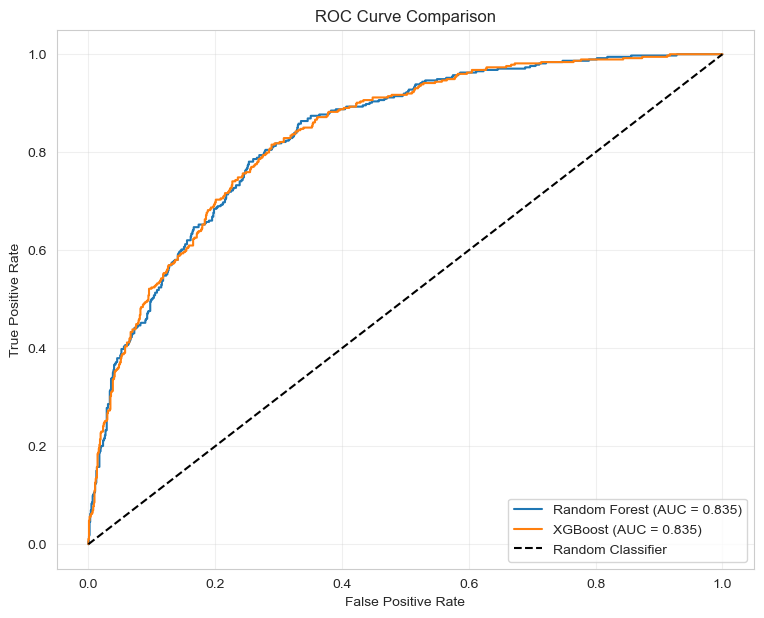

In [22]:

# Calculate ROC curves
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

# Calculate AUC scores
rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

# Plot ROC curves
plt.figure(figsize=(9, 7))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


## 23. Confusion Matrix Comparison

Visualize the confusion matrices of both models to examine correct and incorrect churn predictions.

The matrices show True Positives, True Negatives, False Positives, and False Negatives.

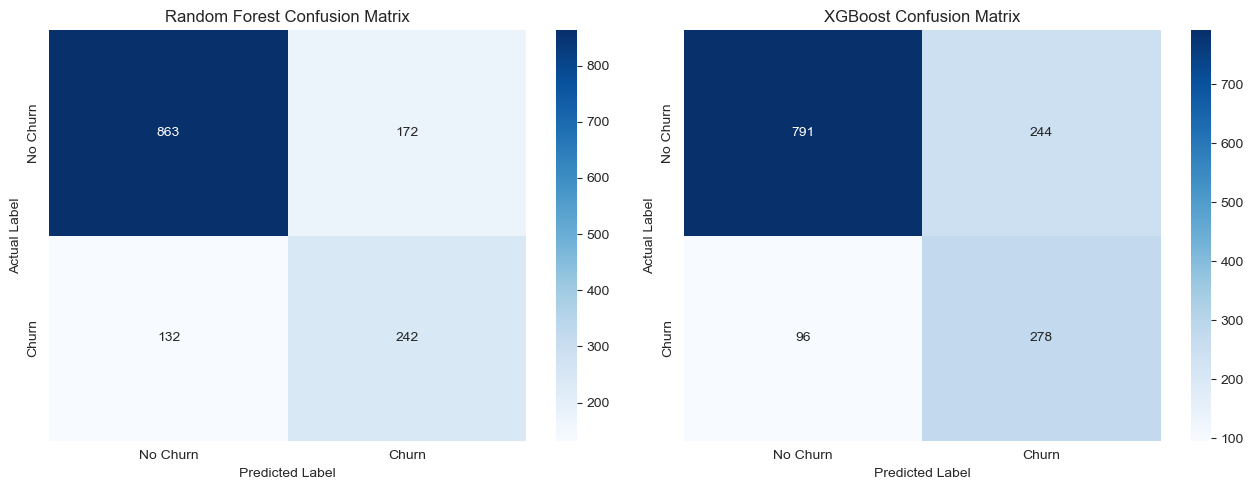

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Random Forest", rf_predictions),
    ("XGBoost", xgb_predictions)
]

for ax, (model_name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


## 24. Feature Importance Analysis

Extract feature importance scores from both ensemble models.

Display the top 10 most influential features to understand which customer characteristics contribute most to churn prediction.

In [24]:

# Get feature names after preprocessing
feature_names = (
    random_forest_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance
rf_importance = random_forest_pipeline.named_steps[
    "model"
].feature_importances_

xgb_importance = xgboost_pipeline.named_steps[
    "model"
].feature_importances_

# Create importance DataFrames
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
}).sort_values(by="Importance", ascending=False)

xgb_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importance
}).sort_values(by="Importance", ascending=False)

# Display top 10 features
print("Random Forest - Top 10 Features")
display(rf_importance_df.head(10))

print("XGBoost - Top 10 Features")
display(xgb_importance_df.head(10))


Random Forest - Top 10 Features


,Feature,Importance
1,numerical__tenure,0.128494
3,numerical__TotalCharges,0.125672
2,numerical__MonthlyCharges,0.099140
36,categorical__Contract_Month-to-month,0.092772
18,categorical__OnlineSecurity_No,0.048161
38,categorical__Contract_Two year,0.044542
27,categorical__TechSupport_No,0.038345
16,categorical__InternetService_Fiber optic,0.037677
43,categorical__PaymentMethod_Electronic check,0.031463
21,categorical__OnlineBackup_No,0.017800


XGBoost - Top 10 Features


,Feature,Importance
36,categorical__Contract_Month-to-month,0.343883
16,categorical__InternetService_Fiber optic,0.100348
18,categorical__OnlineSecurity_No,0.051971
27,categorical__TechSupport_No,0.034466
38,categorical__Contract_Two year,0.033413
17,categorical__InternetService_No,0.029429
15,categorical__InternetService_DSL,0.027074
35,categorical__StreamingMovies_Yes,0.024261
19,categorical__OnlineSecurity_No internet service,0.019059
43,categorical__PaymentMethod_Electronic check,0.018155


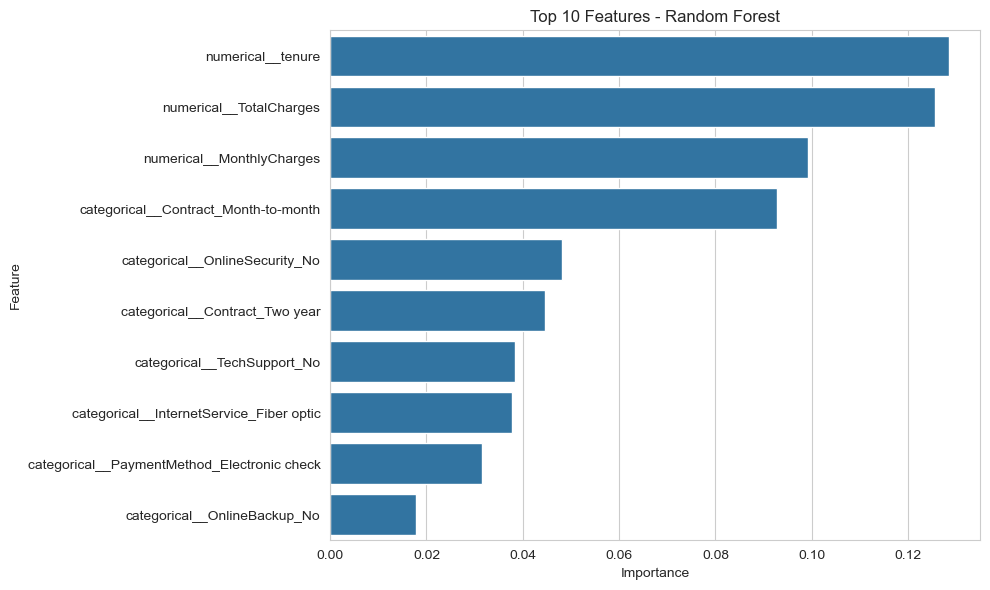

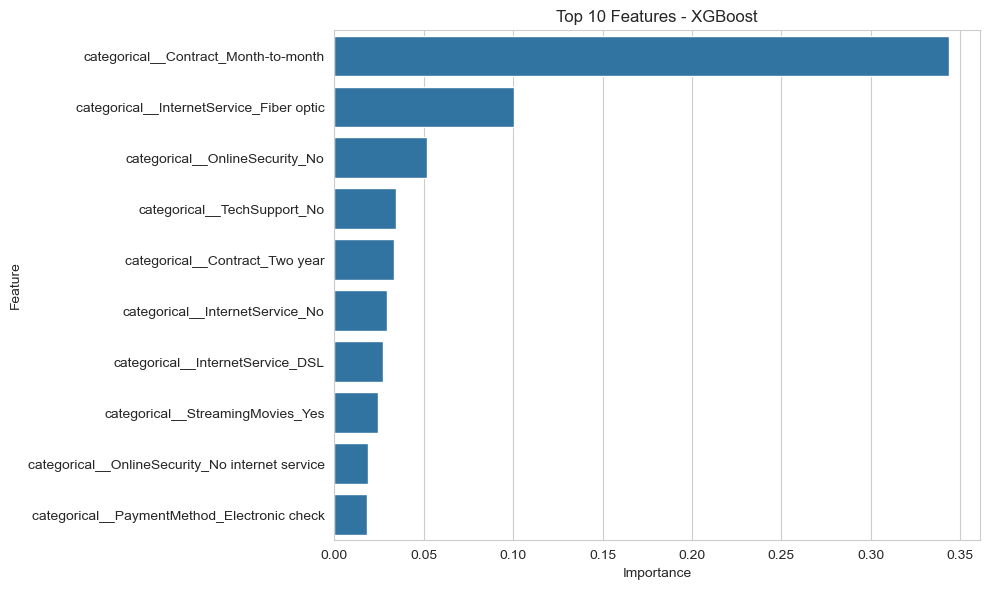

In [25]:

# Plot top 10 Random Forest features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features - Random Forest")
plt.tight_layout()
plt.show()

# Plot top 10 XGBoost features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features - XGBoost")
plt.tight_layout()
plt.show()


## 25. Final Conclusion

This project developed and evaluated two ensemble machine learning models to predict customer churn using the Telco Customer Churn dataset.

### Models Evaluated
- Random Forest Classifier
- XGBoost Classifier

### Key Results

- Random Forest achieved an ROC-AUC score of 0.8347 (83.47%).
- XGBoost achieved an ROC-AUC score of 0.8353 (83.53%).
- Both models exceeded the target ROC-AUC score of 80%.
- XGBoost achieved the highest Recall of 74.33%.
- Random Forest achieved the highest Accuracy of 78.42%.

### Feature Importance

The most influential features included customer tenure, total charges, monthly charges, contract type, and internet service type.

### Final Findings

XGBoost achieved a slightly higher ROC-AUC and Recall, making it useful for identifying customers who are likely to leave.

Random Forest achieved better Accuracy and Precision.

Both models demonstrated good discriminatory performance, although further hyperparameter tuning and threshold optimization could improve their predictive performance.

### Limitations

- The models may require further tuning to improve Precision and Recall.
- Feature importance indicates predictive contribution, not causation.
- The evaluation results are based on a single held-out test set.

Overall, this project demonstrates how ensemble machine learning techniques can help telecommunications companies identify customers at risk of churn.